In [5]:
#loading images
import matplotlib.pyplot as plt
image_1 = plt.imread('images/fig_q1.jpg')

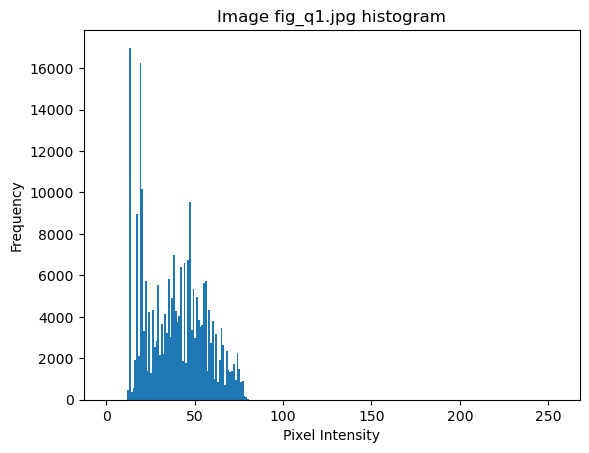

In [11]:
# plotting histogram
plt.hist(image_1.ravel(), bins=256, range=(0, 255)) 

# Optional: Add range=(0, 255) to ensure the x-axis represents 
# standard 8-bit pixel values correctly.

plt.title('Image fig_q1.jpg histogram')
plt.xlabel('Pixel Intensity')
plt.ylabel('Frequency')
plt.show()

<>:21: SyntaxWarning: invalid escape sequence '\g'
<>:21: SyntaxWarning: invalid escape sequence '\g'
C:\Users\hp\AppData\Local\Temp\ipykernel_15740\248355394.py:21: SyntaxWarning: invalid escape sequence '\g'
  ax[1].set_title(f'Power Law Transformed ($\gamma={gamma}$)')


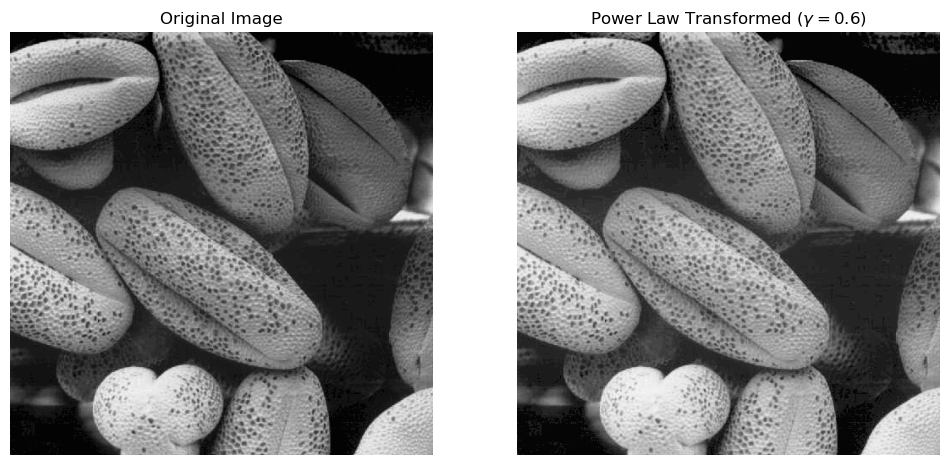

In [19]:
import numpy as np
# If image is integer (0-255), divide by 255.
if image_1.dtype == 'uint8':
    img_float = image_1 / 255.0
else:
    img_float = image_1

# If image is washed out (too bright), use gamma > 1 (e.g., 2.0)
gamma = 0.6  # <--- ADJUST THIS VALUE BASED ON YOUR IMAGE
corrected_img = np.power(img_float, gamma)
# 4. Plot Side-by-Side
fig, ax = plt.subplots(1, 2, figsize=(12, 6))

# Original
ax[0].imshow(img_float, cmap='gray')
ax[0].set_title('Original Image')
ax[0].axis('off')

# Transformed
ax[1].imshow(corrected_img, cmap='gray')
ax[1].set_title(f'Power Law Transformed ($\gamma={gamma}$)')
ax[1].axis('off')

plt.show()

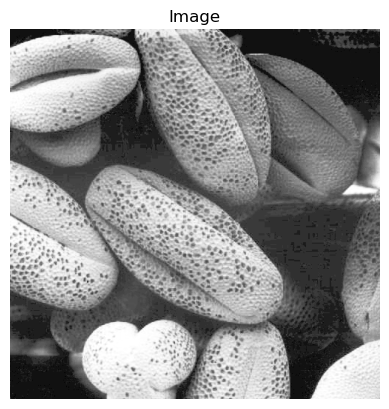

In [21]:
# histogram normalisation
from skimage import exposure
image_1_eq = exposure.equalize_hist(image_1)
def show_image(image, title='Image', cmap_type='gray'):
    plt.imshow(image, cmap=cmap_type)
    plt.title(title)
    plt.axis('off')
    plt.show()

show_image(image_1_eq)

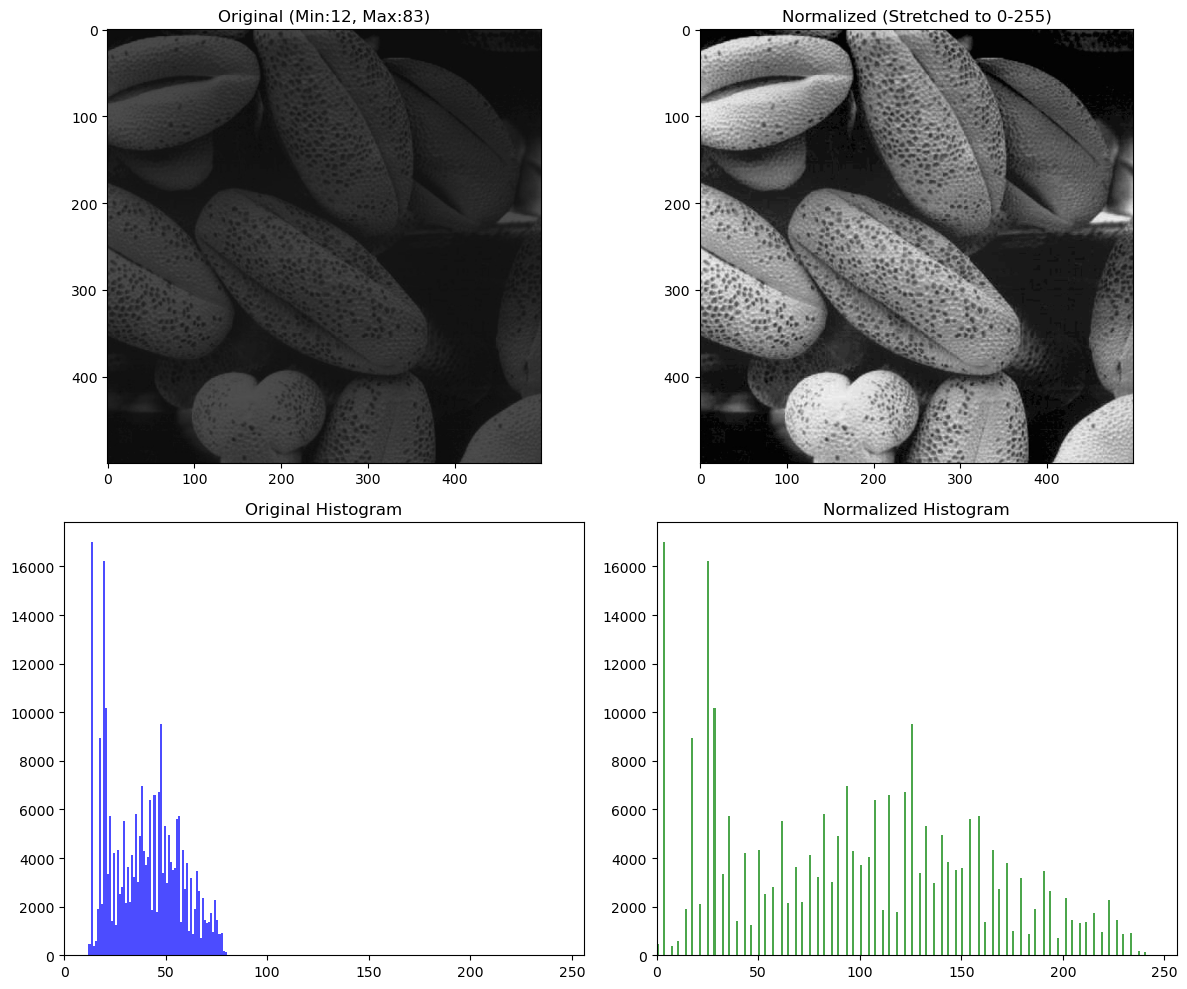

In [25]:
from skimage import color
if image_1.ndim == 3:
    image_1 = color.rgb2gray(img)
    # rgb2gray produces floats 0-1, so we scale back to 0-255 for the histogram to look standard
    image_1 = (image_1 * 255).astype(np.uint8)

# 2. Apply Histogram Normalization (Min-Max Stretching)
img_min = image_1.min()
img_max = image_1.max()

# The Math: (Pixel - Min) / (Range) * 255
# using float calculation to avoid integer overflow, then casting back to uint8
norm_img = (image_1 - img_min) / (img_max - img_min) * 255
norm_img = norm_img.astype(np.uint8)

# 3. Plotting Side-by-Side
fig, axes = plt.subplots(2, 2, figsize=(12, 10))

# Top Left: Original Image
axes[0, 0].imshow(image_1, cmap='gray', vmin=0, vmax=255)
axes[0, 0].set_title(f'Original (Min:{img_min}, Max:{img_max})')

# Top Right: Normalized Image
axes[0, 1].imshow(norm_img, cmap='gray', vmin=0, vmax=255)
axes[0, 1].set_title('Normalized (Stretched to 0-255)')

# Bottom Left: Original Histogram
axes[1, 0].hist(image_1.ravel(), bins=256, range=(0, 256), color='blue', alpha=0.7)
axes[1, 0].set_title('Original Histogram')
axes[1, 0].set_xlim([0, 256])

# Bottom Right: Normalized Histogram
axes[1, 1].hist(norm_img.ravel(), bins=256, range=(0, 256), color='green', alpha=0.7)
axes[1, 1].set_title('Normalized Histogram')
axes[1, 1].set_xlim([0, 256])

plt.tight_layout()
plt.show()

### IMAGE 2

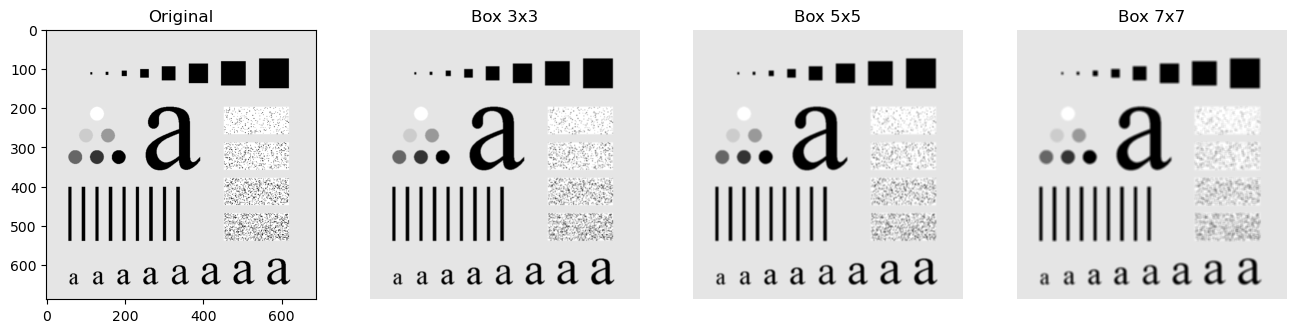

In [30]:

from scipy.signal import convolve2d
from skimage import data

# 1. Load Image (Robust check)
try:
    img = plt.imread('images/fig_q2.jpg')
except FileNotFoundError:
    img = data.camera() # Fallback

if img.ndim == 3:
    img = color.rgb2gray(img)

# 2. Define Helper for Box Filter
def apply_box_filter(image, size):
    # A box kernel is just ones divided by the total area
    kernel = np.ones((size, size)) / (size * size)
    # boundary='symm' handles edges better than zero-padding
    return convolve2d(image, kernel, mode='same', boundary='symm')

# 3. Apply for 3x3, 5x5, 7x7
sizes = [3, 5, 7]
filtered_images = [apply_box_filter(img, s) for s in sizes]

# 4. Plot
fig, axes = plt.subplots(1, 4, figsize=(16, 4))
axes[0].imshow(img, cmap='gray')
axes[0].set_title('Original')

for i, s in enumerate(sizes):
    axes[i+1].imshow(filtered_images[i], cmap='gray')
    axes[i+1].set_title(f'Box {s}x{s}')
    axes[i+1].axis('off')

plt.show()

<>:38: SyntaxWarning: invalid escape sequence '\s'
<>:38: SyntaxWarning: invalid escape sequence '\s'
C:\Users\hp\AppData\Local\Temp\ipykernel_15740\4169567324.py:38: SyntaxWarning: invalid escape sequence '\s'
  ax.set_title(f'Gauss {size}x{size}, $\sigma$={sigma}')


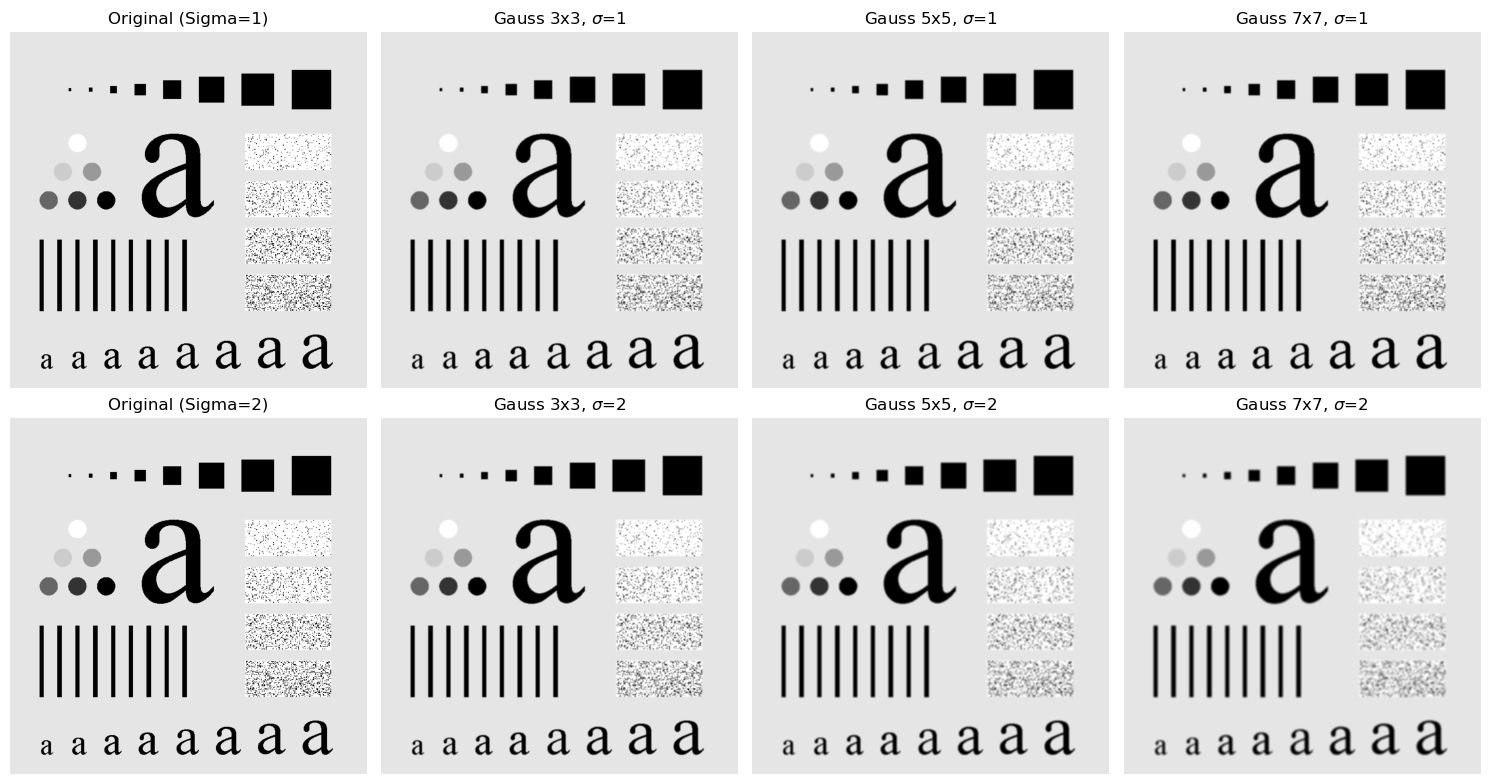

In [32]:


def generate_gaussian_kernel(size, sigma):
    """
    Generates a kernel manually using the formula provided:
    w(s, t) = K * exp( -(s^2 + t^2) / (2*sigma^2) )
    """
    kernel = np.zeros((size, size))
    center = size // 2
    
    # Iterate through the grid (s, t) relative to center
    for x in range(size):
        for y in range(size):
            s = x - center
            t = y - center
            kernel[x, y] = np.exp(-(s**2 + t**2) / (2 * sigma**2))
            
    # Normalize so sum = 1 (Preserve Image Brightness)
    return kernel / np.sum(kernel)

# Setup
sizes = [3, 5, 7]
sigmas = [1, 2] # The question asks for both

# Create a grid of plots
fig, axes = plt.subplots(len(sigmas), len(sizes)+1, figsize=(15, 8))

for row, sigma in enumerate(sigmas):
    # Show Original in first column
    axes[row, 0].imshow(img, cmap='gray')
    axes[row, 0].set_title(f'Original (Sigma={sigma})')
    axes[row, 0].axis('off')
    
    for col, size in enumerate(sizes):
        kernel = generate_gaussian_kernel(size, sigma)
        result = convolve2d(img, kernel, mode='same', boundary='symm')
        
        ax = axes[row, col+1]
        ax.imshow(result, cmap='gray')
        ax.set_title(f'Gauss {size}x{size}, $\sigma$={sigma}')
        ax.axis('off')

plt.tight_layout()
plt.show()